In [ ]:
# ============================================================
# MODEL EVALUATION USING SCIKIT-LEARN
# Dataset: Built-in Breast Cancer Dataset
# ============================================================
# PART 1: IMPORT LIBRARIES
# ------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    learning_curve,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# PART 2: LOAD THE BUILT-IN DATASET
# ------------------------------------------------------------
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
print("\nDataset loaded successfully")


Dataset loaded successfully


In [ ]:
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes:", data.target_names)

Number of rows: 569
Number of features: 30
Target classes: ['malignant' 'benign']


In [ ]:
print("\nFirst five rows:")
X.head()


First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
# PART 3: UNDERSTAND THE DATA
# ------------------------------------------------------------
print("\nDataset information:")
print(X.info())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

In [ ]:
print("\nStatistical summary:")
print(X.describe().round(2))


Statistical summary:
       mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
count       569.00        569.00          569.00     569.00           569.00   
mean         14.13         19.29           91.97     654.89             0.10   
std           3.52          4.30           24.30     351.91             0.01   
min           6.98          9.71           43.79     143.50             0.05   
25%          11.70         16.17           75.17     420.30             0.09   
50%          13.37         18.84           86.24     551.10             0.10   
75%          15.78         21.80          104.10     782.70             0.11   
max          28.11         39.28          188.50    2501.00             0.16   

       mean compactness  mean concavity  mean concave points  mean symmetry  \
count            569.00          569.00               569.00         569.00   
mean               0.10            0.09                 0.05           0.18   
std                0

In [ ]:
print("\nMissing values in each column:")
print(X.isnull().sum())


Missing values in each column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64


In [ ]:
print("\nDuplicate rows:", X.duplicated().sum())


Duplicate rows: 0


In [ ]:
# PART 4: UNDERSTAND THE TARGET VARIABLE
# ------------------------------------------------------------
print("\nTarget counts:")
print(y.value_counts().sort_index())

print("\nTarget class names:")
print(data.target_names)


Target counts:
target
0    212
1    357
Name: count, dtype: int64

Target class names:
['malignant' 'benign']


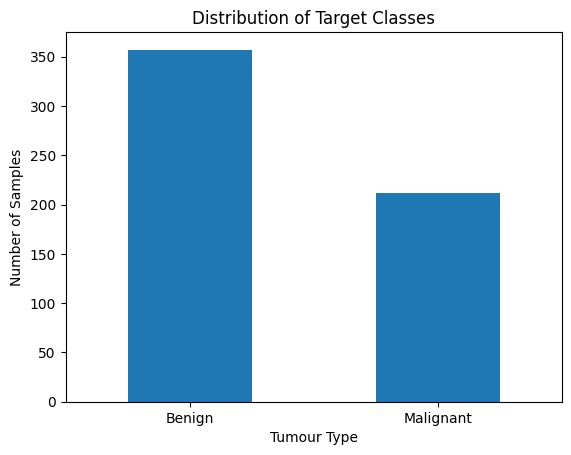

In [ ]:
y_names = y.map({0: "Malignant", 1: "Benign"})

y_names.value_counts().plot(kind="bar")
plt.title("Distribution of Target Classes")
plt.xlabel("Tumour Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()


In [ ]:
# PART 5: CHECK CLASS BALANCE
# ------------------------------------------------------------

class_percentages = y.value_counts(normalize=True) * 100

print("\nClass percentages:")
print(class_percentages.round(2))

print("\nWhy check class balance?")
print("Accuracy alone may be misleading when classes are imbalanced.")


Class percentages:
target
1    62.74
0    37.26
Name: proportion, dtype: float64

Why check class balance?
Accuracy alone may be misleading when classes are imbalanced.


In [ ]:
# PART 6: SPLIT DATA INTO TRAINING AND TEST SETS
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))




Training rows: 455
Testing rows: 114

Training target proportions:
target
1    0.626
0    0.374
Name: proportion, dtype: float64

Testing target proportions:
target
1    0.632
0    0.368
Name: proportion, dtype: float64


In [ ]:
# PART 7: CREATE A SIMPLE BASELINE MODEL
# ------------------------------------------------------------
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

print("\nBaseline accuracy:", round(baseline_accuracy, 4))
# A baseline gives us a simple result to beat.



Baseline accuracy: 0.6316


In [ ]:

# PART 8: BUILD A LOGISTIC REGRESSION PIPELINE
# ------------------------------------------------------------
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000))
])

logistic_model.fit(X_train, y_train)

predictions = logistic_model.predict(X_test)

print("\nLogistic Regression model trained!")
# PART 9: CALCULATE FOUR IMPORTANT METRICS
# ------------------------------------------------------------
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, zero_division=0)
recall = recall_score(y_test, predictions, zero_division=0)
f1 = f1_score(y_test, predictions, zero_division=0)
print("\nMODEL EVALUATION")
print("------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

# Accuracy  = Overall proportion of correct predictions.
# Precision = Of predicted positives, how many were positive?
# Recall    = Of actual positives, how many were detected?
# F1        = Harmonic mean of precision and recall.
#
# Here, class 1 is benign.
# In medical screening, also examine recall for malignant cases.


Logistic Regression model trained!

MODEL EVALUATION
------------------------------
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1 Score : 0.9861


In [ ]:
# PART 10: PRINT THE CLASSIFICATION REPORT
# ------------------------------------------------------------
print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        predictions,
        target_names=data.target_names,
        zero_division=0
    )
)


Confusion Matrix:
[[41  1]
 [ 1 71]]


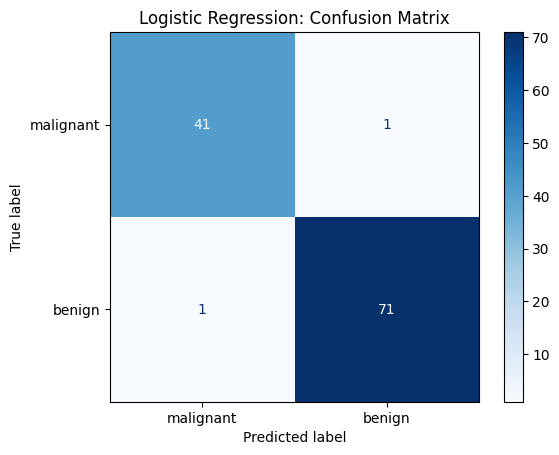

In [ ]:
# PART 11: CONFUSION MATRIX
# ------------------------------------------------------------
cm = confusion_matrix(y_test, predictions)

print("\nConfusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(cmap="Blues")

plt.title("Logistic Regression: Confusion Matrix")
plt.show()

In [ ]:
# PART 12: COMPARE THREE CLASSIFICATION MODELS
# ------------------------------------------------------------

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)
    model_predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, model_predictions),
        "Precision": precision_score(
            y_test, model_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, model_predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, model_predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON:")
print(results_df.round(4).to_string(index=False))


MODEL COMPARISON:
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.9825     0.9861  0.9861    0.9861
      Decision Tree    0.9386     0.9577  0.9444    0.9510
      Random Forest    0.9561     0.9589  0.9722    0.9655


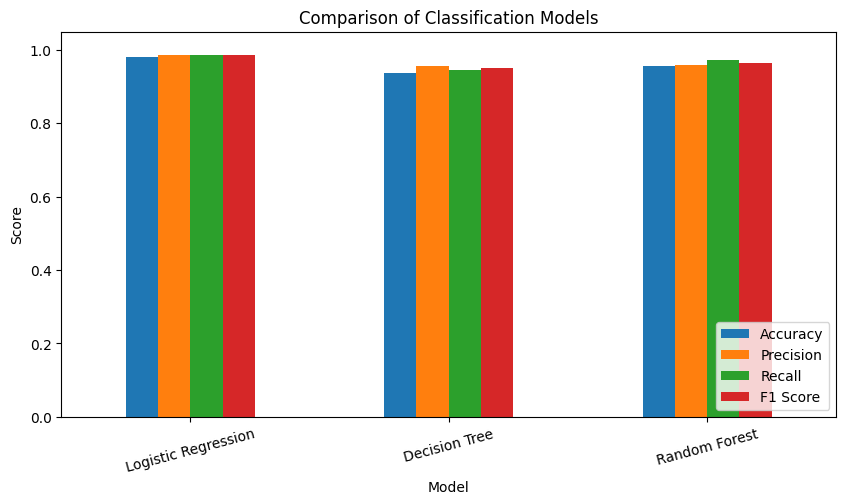

In [ ]:
# PART 13: VISUALIZE MODEL COMPARISON
# ------------------------------------------------------------

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.show()


In [ ]:
# PART 14: INTRODUCTION TO CROSS-VALIDATION
# ------------------------------------------------------------

# Instead of evaluating on just one split,
# cross-validation evaluates multiple train/validation splits.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("\nFive-Fold Cross-Validation Scores:")
print(np.round(cv_scores, 4))

print("Mean CV accuracy:", round(cv_scores.mean(), 4))
print("Standard deviation:", round(cv_scores.std(), 4))

# A large standard deviation may indicate unstable performance.
# Cross-validation here uses only the training partition.


Five-Fold Cross-Validation Scores:
[0.967 0.989 0.978 0.989 0.967]
Mean CV accuracy: 0.978
Standard deviation: 0.0098


In [ ]:
# PART 15: COMPARE MODELS USING CROSS-VALIDATION
# ------------------------------------------------------------

cv_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Decision Tree": models["Decision Tree"],
    "Random Forest": models["Random Forest"]
}

cv_results = []

for name, model in cv_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION COMPARISON:")
print(cv_df.round(4).to_string(index=False))




CROSS-VALIDATION COMPARISON:
              Model  Mean CV Accuracy  CV Standard Deviation
Logistic Regression            0.9780                 0.0098
      Decision Tree            0.9297                 0.0149
      Random Forest            0.9626                 0.0179
